In [63]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [64]:
import numpy as np
from mytools.data import read_h5, vitems
from mytools.plot import plot_heatmap,save_plot, plot_sector
from mytools.plot_custom import plot_stack_fit_res, compare_profiles
%matplotlib inline

# load data

In [65]:
result_path = "../data/crafts_df122k_xsize3000_nfs10_mean_numerical_result.h5"
vitems(result_path)

Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/fitted
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/jk_mean_residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/jk_std
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/peak_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/residual
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_arpls_rmfg_xsize3000_nfs10/stack
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10
Type:

In [66]:
grp_key = 'crafts_df122k_arpls_rmfg_xsize3000_nfs10'
stacked, fitted, res_jk, jk_std, peak_mask = read_h5(result_path, [grp_key+'/'+ s for s in ['stack', 'fitted', 'jk_mean_residual', 'jk_std', 'peak_mask']])

<Axes: title={'center': 'Jackknife error'}, xlabel='X', ylabel='Y'>

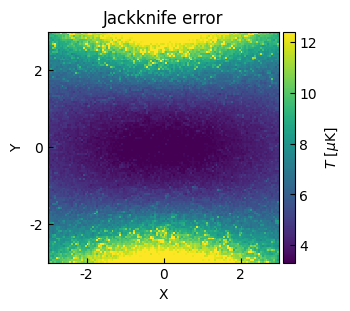

In [67]:
stack_result_masked = np.ma.masked_array(stacked, peak_mask)
fitted = np.ma.masked_array(fitted, peak_mask)

plot_heatmap(jk_std, title='Jackknife error')

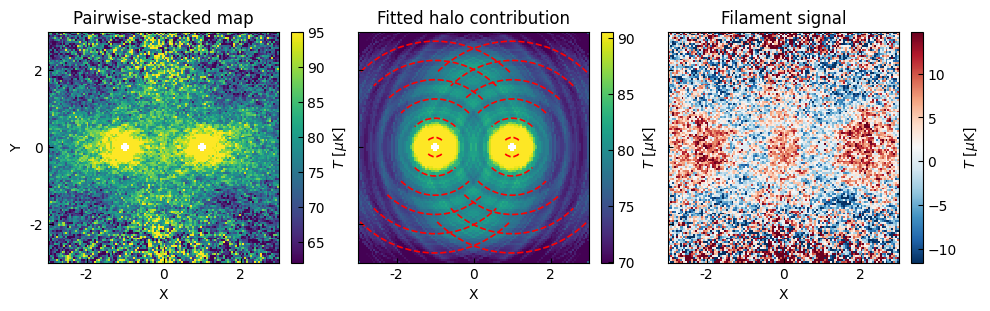

In [68]:
axes = plot_stack_fit_res(
    [stack_result_masked, fitted, res_jk],  # pyright: ignore[reportArgumentType]
    norm="linear",
    cmap=["viridis", "viridis", "RdBu_r"],
    # vmax=[140, 140, 15],
    # vmin=[60, 60, -15],
)
plot_sector(axes[1], ec='r')
fname = "img_crafts_halofitting_numerical_stack_fit_res.png"
# save_plot(axes, fname)

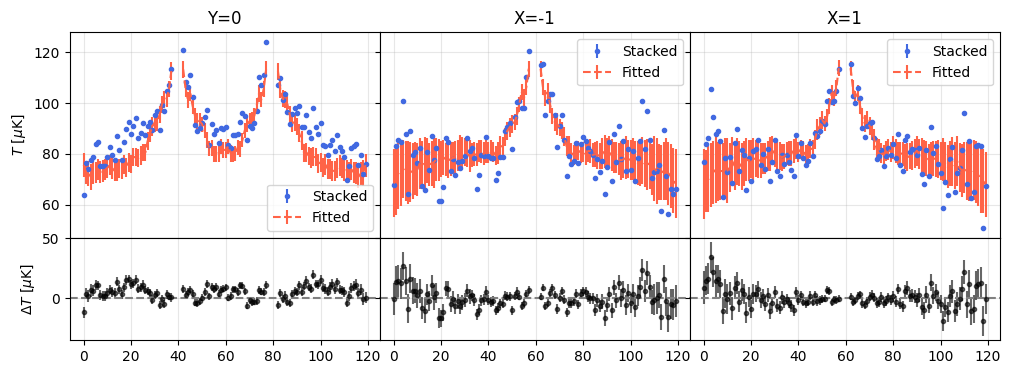

In [107]:
compare_profiles(
    [stack_result_masked, fitted], 
    err_list=[np.zeros_like(stacked), jk_std],
);

# Estimate filament signal level

In [76]:
from mytools.estimate_err import get_signal_level
from mytools.plot_custom import plot_profile_2c

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(2.8834817309356073), np.float64(0.0), np.float64(0.2565235817018169), np.float64(2.7705069768724977)]
Gauss fit covariance (without fix mean): 
[[ 0.06350463  0.00091226 -0.0308075 ]
 [ 0.00091226  0.00099068 -0.0043531 ]
 [-0.0308075  -0.0043531   0.03898721]]
0 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 53.240
Reduced chi-squared: 1.439
RMS residual: 1.154

width: 0.2565235817018169
width_pix: 5


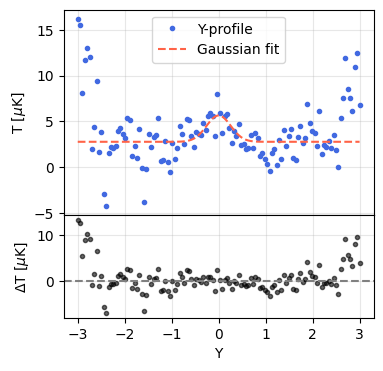

In [108]:
bounds = {
    "amplitude_0": (0, np.inf),  # amplitude
    "stddev_0": (0, 0.6),  # sigma
}

lx, ly, ly_err, clrb, clrb_err, params, cov = get_signal_level(
    res_jk, jk_std, 
    bounds=bounds, 
    show_fit=True, 
    print_info=True, 
    fit_range=[-1,1],
)

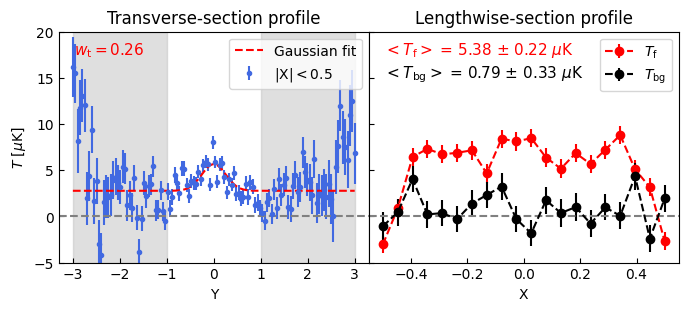

In [185]:
# text_pos = [[-0.35, 12], [-0.38, 10], [-2, 10]]
text_pos=None
axes = plot_profile_2c(
    lx, ly, 
    y_err=ly_err, 
    width=params[2], 
    fontsize=11, 
    text_pos=text_pos,
    color=['royalblue', 'r', 'r', 'k'],
)
axes[0].set_ylim(-5, 20)
axes[0].axvspan(-3, -1, color='silver', alpha=0.5)
axes[0].axvspan(3, 1, color='silver', alpha=0.5,)
# axes[0].axvspan(-1,1, color='wheat', alpha=1,)

fname = 'img_crafts_halofitting_numerical_signal.png'
# save_plot(axes, fname)